In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
from polyergalio.models.network import Network
from polyergalio.visuals.nnet_visuals import plot_network
from polyergalio.models.model_loss import MSELoss
from polyergalio.models.optimizers import SGD, Adam
from polyergalio.models.layers import (
    FullyConnectedLayer,
    DropoutLayer,
    NormalizeLayer,
    RMSNormLayer,
    FrequencyFFT,
    SpectreAttention,
    LatentExpand,
    SpectreDecoderAttention,
    SpectrePooledAttention,
    MixtureOfExperts,
    LatentStack, LatentSum, ShiftRight, PoolingLayer
)
from polyergalio.profiling import Profiler
from polyergalio.models.embedding.positional import SinusoidEmbedding, RopeEmbedding

import matplotlib.pyplot as plt

# MAX_POSSIBLE_WINDOWS = 2**10


In [2]:
from polyergalio.encoders.audio_encoders import (AudioProcessor,
                                              read_wav,
                                              window_size_from_ms,
                                              plot_waveform,
                                              plot_spectrogram,
                                              plot_window_spectra,
                                              build_windows,
                                              progressive_downsample)

WINDOW_LENGTH_MS = 600 # our window length for plotting
sample_rate, waveform_l = read_wav("../test.wav", channel=0)
sample_rate, waveform_r = read_wav("../test.wav", channel=1)

time_per_sample = 1000 / sample_rate
samples_per_window = window_size_from_ms(sample_rate, WINDOW_LENGTH_MS)
# samples_per_window = WINDOW_LENGTH_MS / time_per_sample
real_positive_fft_shape = (samples_per_window // 2) + 1


print(time_per_sample, "ms per sample step")
print(f"Each {WINDOW_LENGTH_MS} ms window will be composed of {samples_per_window} samples")
print(f"Fourier Transform will yield {real_positive_fft_shape} frequency bins")

audio_enc = AudioProcessor(
    sample_rate=sample_rate,
    window_ms = WINDOW_LENGTH_MS,
    overlap_ratio= 1/3, # how much of the window is overlapping with previous step
    use_decibels = True,
    target = "waveform",
)


encoded_data = audio_enc.fit_encode(waveform_l)
print(audio_enc.metadata)
print("amplitude", encoded_data["amplitude"].shape, "\nfrequency spectrum:", encoded_data["spectrum"].shape)


0.010416666666666666 ms per sample step
Each 600 ms window will be composed of 57600 samples
Fourier Transform will yield 28801 frequency bins
{'target': 'waveform', 'channel': 0, 'sample_rate': 96000, 'window_ms': 600, 'window_size': 57600, 'num_overlap': 19200, 'num_frequencies': 28801, 'use_decibels': True}
amplitude (19, 57600) 
frequency spectrum: (19, 28801)


/Users/david/Library/CloudStorage/Dropbox/CODE/tools/ml-tools/src/polyergalio/encoders/audio_encoders.py:108: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, waveform = wavfile.read(file_path)


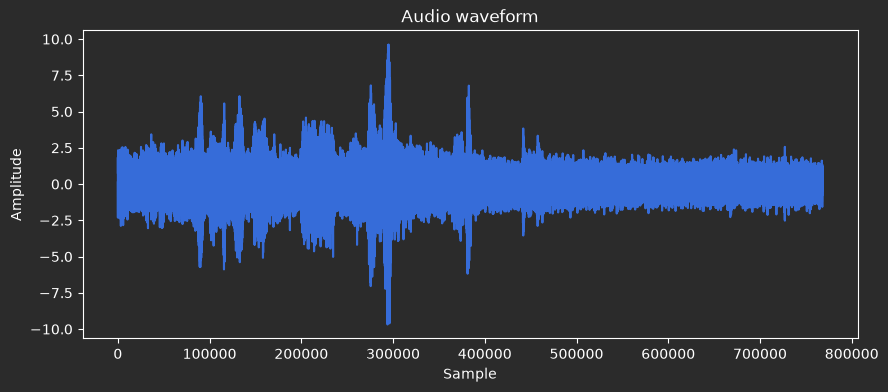

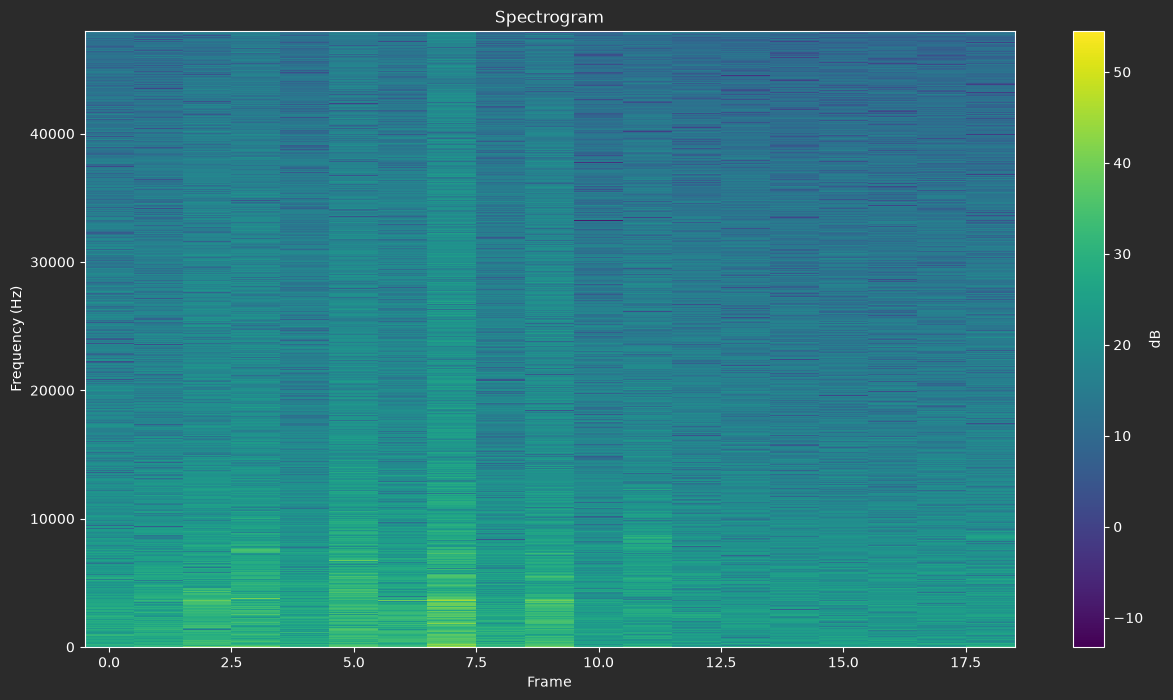

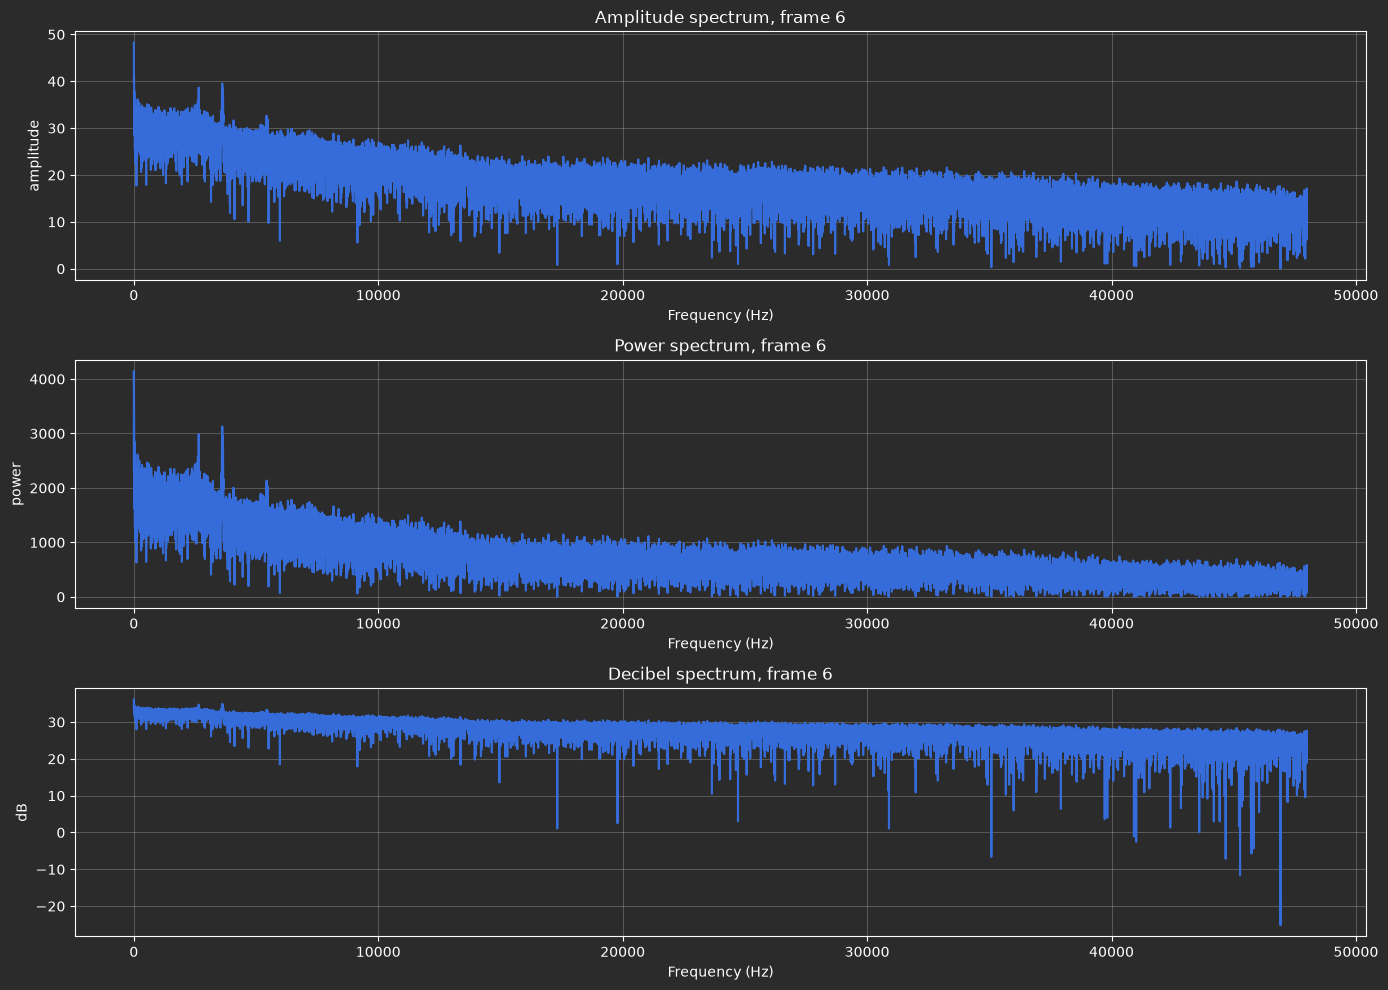

In [3]:
plot_waveform(waveform_l)
plot_spectrogram(encoded_data["spectrum"].real, audio_enc.freqs)
plot_window_spectra(
        encoded_data["spectrum"].real, audio_enc.freqs, index=6, window_size=time_per_sample
    )


In [4]:
# loading our audio files:
import os
WINDOW_LENGTH_MS = 50 # our window length

all_windowed_data = []

all_filenames = os.listdir(f"../data/")
for fn in all_filenames:
    if fn.endswith(".wav"):

        sample_rate, waveform_l = read_wav(f"../data/{fn}", channel=0)
        time_per_sample = 1000 / sample_rate
        samples_per_window = window_size_from_ms(sample_rate, WINDOW_LENGTH_MS)
        # samples_per_window = WINDOW_LENGTH_MS / time_per_sample
        real_positive_fft_shape = (samples_per_window // 2) + 1


        audio_enc = AudioProcessor(
            sample_rate=sample_rate,
            window_ms = WINDOW_LENGTH_MS,
            overlap_ratio= 1/4, # how much of the window is overlapping with previous step
            use_decibels = True,
            target = "waveform",
        )

        encoded_data_l = audio_enc.fit_encode(waveform_l)["amplitude"]
        list_of_array = [encoded_data_l]

        try:
            sample_rate, waveform_r = read_wav(f"../data/{fn}", channel=1)
            encoded_data_r = audio_enc.fit_encode(waveform_r)["amplitude"]
            list_of_array.append(encoded_data_r)
        except:
            pass

        all_windowed_data.extend(list_of_array)

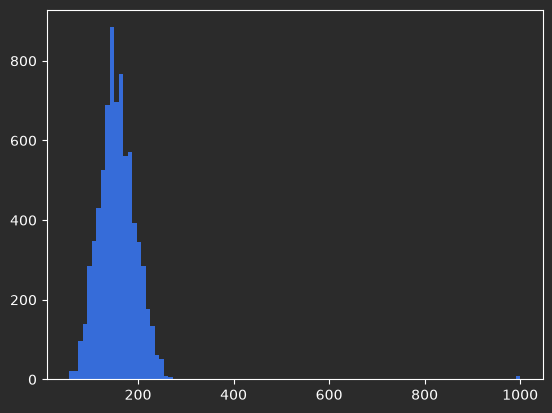

3941


In [5]:
shapes = []
np.random.shuffle(all_windowed_data)

for windowed_data in all_windowed_data:
    shapes.append(windowed_data.shape[0])

plt.hist(np.clip(shapes, min=0, max=1000), bins=100)
plt.show()
print(np.max(shapes))

In [6]:
# MAX_POSSIBLE_WINDOWS should be optimized for specific lengths of FFT: closest to: (2**10 * N)
# MAX_POSSIBLE_WINDOWS = 2**10 * 1
MAX_POSSIBLE_WINDOWS = 600


# pad our sequences to max:
xs = np.zeros((len(all_windowed_data), MAX_POSSIBLE_WINDOWS, samples_per_window))
padding_mask = np.zeros((len(all_windowed_data), MAX_POSSIBLE_WINDOWS))
for idx, data in enumerate(all_windowed_data):
    l, n = data.shape
    l = min(l, MAX_POSSIBLE_WINDOWS)
    xs[idx, :l, :] = data[:l, ...]
    padding_mask[idx, :l] = 1

print(xs.shape)
print(padding_mask.shape)

(7504, 600, 200)
(7504, 600)


In [7]:
# downsample the data -- this could be helpful? or not... not sure yet.
#
# downs = progressive_downsample(xs, mask=padding_mask, factors=[2, 2, 2])
#
# for dim in downs:
#     print(dim[0].shape, dim[1].shape)

# let's take a subsample of the data
# xs = xs[:500, ...]
# padding_mask = padding_mask[:500, ...]

In [8]:
print(xs.shape, padding_mask.shape)

(7504, 600, 200) (7504, 600)


In [9]:
from polyergalio.models.network import Network
from polyergalio.visuals.nnet_visuals import plot_network


EMBEDDING_DIM = 1200
HIDDEN_DIM = 1000
# MAX_POSSIBLE_WINDOWS
NUM_HEADS=20
# latent space bottleneck
LATENT_DIMENSION = 1200

# samples_per_window = the samples per window (final dimesion of xs)

print(samples_per_window)
print(MAX_POSSIBLE_WINDOWS)


net = Network(name="audio_encoder_decoder", input_shape=(samples_per_window,))
windows = net.input

# (num_samples, seq_length, window_dimension)
# amplitude branch: funnel the raw window down to the latent width
# project the single-point amplitude data into embedding space
amplitude = net.connect(FullyConnectedLayer(samples_per_window, EMBEDDING_DIM, "linear"), windows, name="amp_embedding")
# embed positional information
amplitude = net.connect(RopeEmbedding(MAX_POSSIBLE_WINDOWS, EMBEDDING_DIM),
                        amplitude, name="amp_position")

amplitude = net.connect(SpectreAttention(sequence_length=MAX_POSSIBLE_WINDOWS,
                                    hidden_dimension=EMBEDDING_DIM,
                                    num_heads=NUM_HEADS,
                                    band_radius=20,
                                    memory_tokens=150,
                                    use_positional_phase=True,
                                    use_wrm=True),
                   amplitude, name="amp_attn")


frequency = net.connect(FrequencyFFT(MAX_POSSIBLE_WINDOWS, samples_per_window),
                        windows, name="freq_fft")
frequency = net.connect(FullyConnectedLayer(samples_per_window, EMBEDDING_DIM, "linear"),
                        frequency, name="freq_embedding")
frequency = net.connect(SpectreAttention(sequence_length=MAX_POSSIBLE_WINDOWS,
                                    hidden_dimension=EMBEDDING_DIM,
                                    num_heads=NUM_HEADS,
                                    band_radius=20,
                                    memory_tokens=150,
                                    use_wrm=True),
                   frequency, name="freq_attn")

# the branches merge, then get positional information
mixed = net.connect(LatentStack(), amplitude, frequency, name="stack")
# down project & mix the hidden dimensions
mixed = net.connect(
    FullyConnectedLayer(input_dimension=2*EMBEDDING_DIM,
                        output_dimension=HIDDEN_DIM,
                        activation_type="linear"),
    mixed,
    name="project")
mixed = net.connect(NormalizeLayer(input_dimension=HIDDEN_DIM, shift_scale=True), mixed, name="mixing_norm")

## Encoder ----------------------------------------------------------------------
enc = net.connect(SpectreAttention(sequence_length=MAX_POSSIBLE_WINDOWS,
                                    hidden_dimension=HIDDEN_DIM,
                                    num_heads=NUM_HEADS,
                                    band_radius=20,
                                    memory_tokens=150,
                                    use_wrm=True),
                   mixed, name="enc0_attn")
enc = net.connect(FullyConnectedLayer(HIDDEN_DIM, HIDDEN_DIM, "swish"), enc, name="enc0_a")
enc = net.connect(DropoutLayer(dropout_prob=0.05), enc, name="enc0_drop")

for _ in range(1, 12):
    enc = net.connect(LatentSum(), mixed, enc, name=f"enc{_}_residualconn")
    enc = net.connect(RMSNormLayer(input_dimension=HIDDEN_DIM), enc, name=f"enc{_}_prenorm")
    enc = net.connect(SpectreAttention(sequence_length=MAX_POSSIBLE_WINDOWS,
                                        hidden_dimension=HIDDEN_DIM,
                                        num_heads=NUM_HEADS,
                                        band_radius=10,
                                        memory_tokens=150,
                                        use_wrm=True), enc, name=f"enc{_}_attn")
    enc = net.connect(FullyConnectedLayer(HIDDEN_DIM, HIDDEN_DIM, "swish"),
                       enc, name=f"enc{_}_a")
    enc = net.connect(DropoutLayer(dropout_prob=0.05), enc, name=f"enc{_}_drop")


# Latent - pool / project down to a single value in sequence ----------------------------
latent = net.connect(LatentSum(), mixed, enc, name="latentresid")
latent = net.connect(RMSNormLayer(HIDDEN_DIM), latent, name="latent_prenorm")

latent = net.connect(SpectrePooledAttention(sequence_length=MAX_POSSIBLE_WINDOWS,
                                            hidden_dimension=HIDDEN_DIM,
                                            num_heads=NUM_HEADS,
                                            band_radius=10,
                                            memory_tokens=300,
                                             ),
                     latent, name="latent_pooled")


# DECODER --------------------------------------------------------------------------------
decoder_in = net.connect(LatentExpand(MAX_POSSIBLE_WINDOWS, HIDDEN_DIM), latent, name="dec_in")

i=0
decoder = net.connect(RMSNormLayer(HIDDEN_DIM), decoder_in, name=f"dec{i}_prenorm")
decoder = net.connect(SpectreAttention(sequence_length=MAX_POSSIBLE_WINDOWS,
                                       hidden_dimension=HIDDEN_DIM,
                                       num_heads=NUM_HEADS,
                                       band_radius=10,
                                       memory_tokens=150,
                                       use_wrm=True),
                  decoder, name=f"dec{i}_attn")
decoder = net.connect(LatentSum(), decoder_in, decoder, name=f"dec{i}_residual")
decoder = net.connect(FullyConnectedLayer(HIDDEN_DIM, HIDDEN_DIM, "swish"), decoder, name=f"dec{i}_fc")

for i in range(1, 4):
    decoder = net.connect(RMSNormLayer(HIDDEN_DIM), decoder, name=f"dec{i}_prenorm")
    decoder = net.connect(SpectreAttention(sequence_length=MAX_POSSIBLE_WINDOWS,
                                           hidden_dimension=HIDDEN_DIM,
                                           num_heads=NUM_HEADS,
                                           band_radius=5,
                                           memory_tokens=150,
                                           use_wrm=True),
                      decoder, name=f"dec{i}_attn")
    decoder = net.connect(FullyConnectedLayer(HIDDEN_DIM, HIDDEN_DIM, "swish"),
                       decoder, name=f"dec{i}_a")
    decoder = net.connect(DropoutLayer(dropout_prob=0.05), decoder, name=f"dec{i}_drop")
    decoder = net.connect(LatentSum(), decoder_in, decoder, name=f"dec{i}_residual")


head = net.connect(MixtureOfExperts(input_dim=HIDDEN_DIM,
                                    upscale_dim=int(1.5*HIDDEN_DIM),
                                    hidden_dim=HIDDEN_DIM,
                                    num_shared_experts=2,
                                    num_routed_experts=48,
                                    top_k=8,
                                    activation_type="swish",
                                    gate_activation="sigmoid",
                                    routed_scaling=1.25,
                                    num_groups=24,
                                    top_groups=12),
                   decoder,
                   name="moe_head")

head = net.connect(NormalizeLayer(HIDDEN_DIM, shift_scale=True), head, name="head_norm")

head = net.connect(FullyConnectedLayer(HIDDEN_DIM, samples_per_window, "linear", is_output=True),
                         head,
                         name="head_output")

net.output = head


net.recast(data_type=np.float32, complex_data_type=np.complex64)

print("edges:")
for producer, consumer in net.edges():
    print(f"  {producer:10s} -> {consumer}")


200
600
edges:
  input      -> amp_embedding
  amp_embedding -> amp_position
  amp_position -> amp_attn
  input      -> freq_fft
  freq_fft   -> freq_embedding
  freq_embedding -> freq_attn
  amp_attn   -> stack
  freq_attn  -> stack
  stack      -> project
  project    -> mixing_norm
  mixing_norm -> enc0_attn
  enc0_attn  -> enc0_a
  enc0_a     -> enc0_drop
  mixing_norm -> enc1_residualconn
  enc0_drop  -> enc1_residualconn
  enc1_residualconn -> enc1_prenorm
  enc1_prenorm -> enc1_attn
  enc1_attn  -> enc1_a
  enc1_a     -> enc1_drop
  mixing_norm -> enc2_residualconn
  enc1_drop  -> enc2_residualconn
  enc2_residualconn -> enc2_prenorm
  enc2_prenorm -> enc2_attn
  enc2_attn  -> enc2_a
  enc2_a     -> enc2_drop
  mixing_norm -> enc3_residualconn
  enc2_drop  -> enc3_residualconn
  enc3_residualconn -> enc3_prenorm
  enc3_prenorm -> enc3_attn
  enc3_attn  -> enc3_a
  enc3_a     -> enc3_drop
  mixing_norm -> enc4_residualconn
  enc3_drop  -> enc4_residualconn
  enc4_residualconn -> 


audio_encoder_decoder: 93 nodes, 303496034 parameters
  node                sources                    shape
  amp_embedding       input                      (1200,)
  amp_position        amp_embedding              (1200,)
  amp_attn            amp_position               (1200,)
  freq_fft            input                      (None, 200)
  freq_embedding      freq_fft                   (1200,)
  freq_attn           freq_embedding             (1200,)
  stack               amp_attn,freq_attn         (2400,)
  project             stack                      (1000,)
  mixing_norm         project                    (1000,)
  enc0_attn           mixing_norm                (1000,)
  enc0_a              enc0_attn                  (1000,)
  enc0_drop           enc0_a                     (1000,)
  enc1_residualconn   mixing_norm,enc0_drop      (None,)
  enc1_prenorm        enc1_residualconn          (1000,)
  enc1_attn           enc1_prenorm               (1000,)
  enc1_a              enc1_attn

<Axes: title={'center': 'audio_encoder_decoder'}>

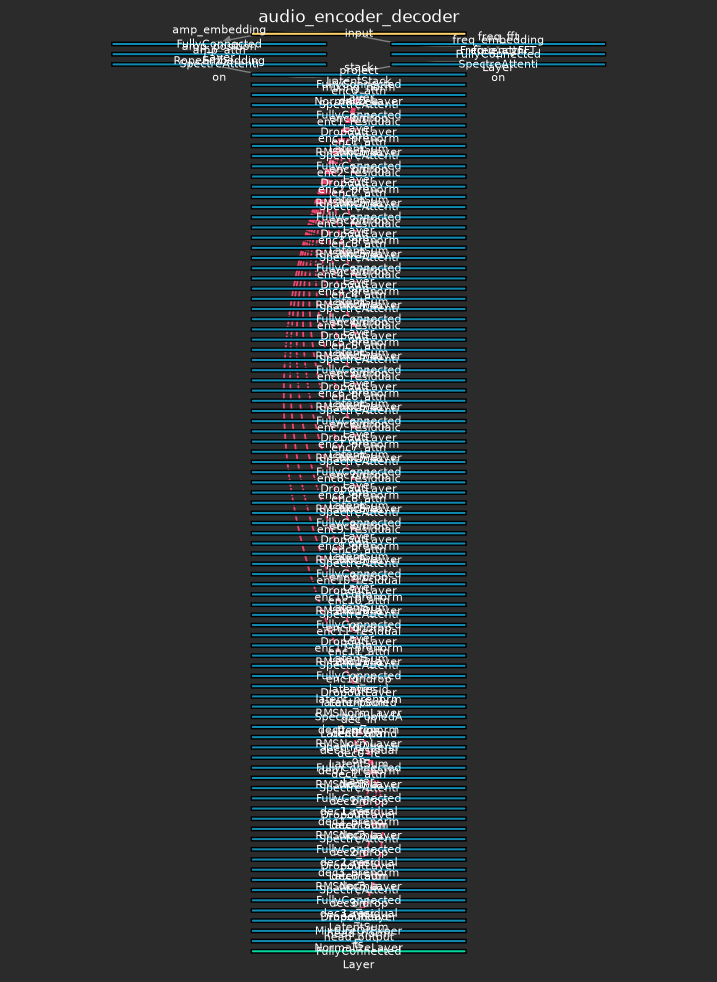

In [10]:
print()
print(net.summary())
plot_network(net)

In [15]:
profiler = Profiler()

net.eval()
with profiler:
    output = profiler.call(net.forward, xs[0:2, ...], label="eval_forward x5", num_loops=5)

net.train()
with profiler:
    output = profiler.call(net.forward, xs[0:2, ...], label="train_forward x5", num_loops=5)

print(profiler.summary())


label             calls   mean ms    min ms    max ms    self ms  self %   net MB  peak MB   min MB   max MB
------------------------------------------------------------------------------------------------------------
train_forward x5      5   2491.95   1364.78   4041.58   12459.76    70.0   389.10  1304.39   908.12  2777.09
eval_forward x5       5   1068.11    792.34   2097.84    5340.55    30.0    30.69   871.86   841.55   993.09


In [12]:
net

Network(93 nodes, 303496034 parameters)

In [13]:
net.deserialize("elephant_spectre_enc_dec_reconstruction.ergalio")

Network(93 nodes, 303496034 parameters)

Automatic pdb calling has been turned ON
EPOCH 1, lr decaying to 0.0006
step   10  reconstruction loss 80.01528008009967


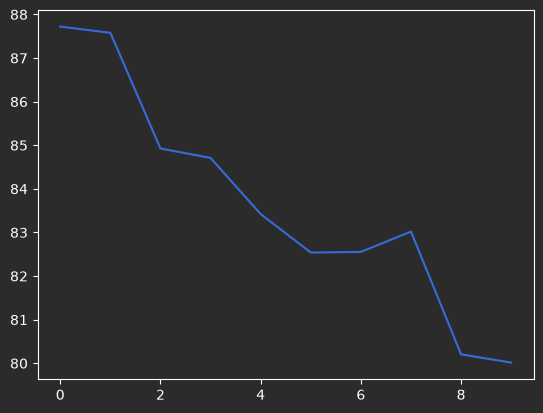

step   10  reconstruction loss 76.92885218751951


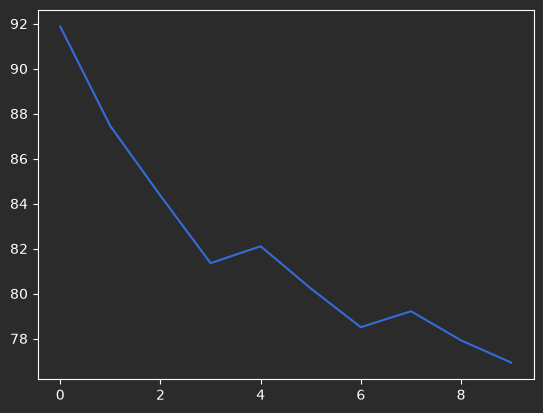

step   10  reconstruction loss 93.6706493163284


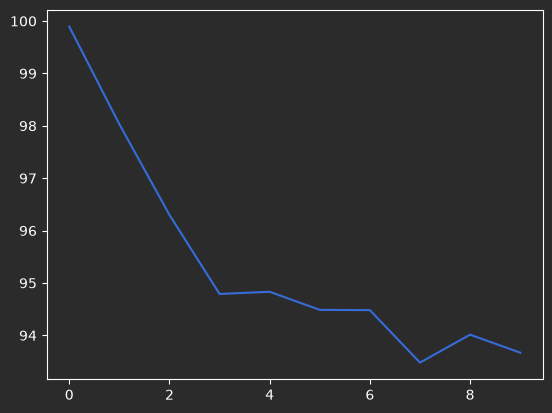

step   10  reconstruction loss 93.41741936049833


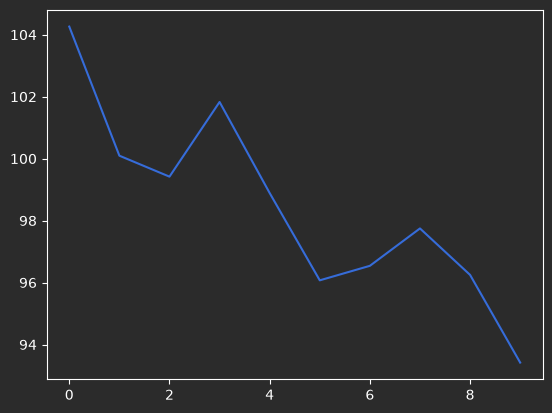

step   10  reconstruction loss 80.98427068875644


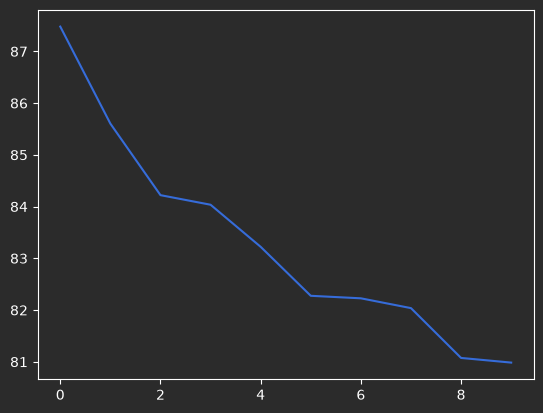

step   10  reconstruction loss 80.11953091981124


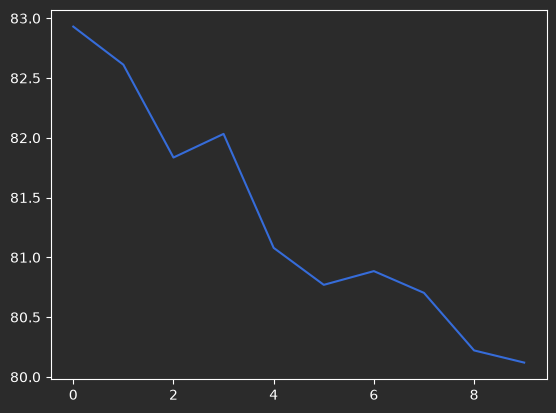

step   10  reconstruction loss 83.0624458275438


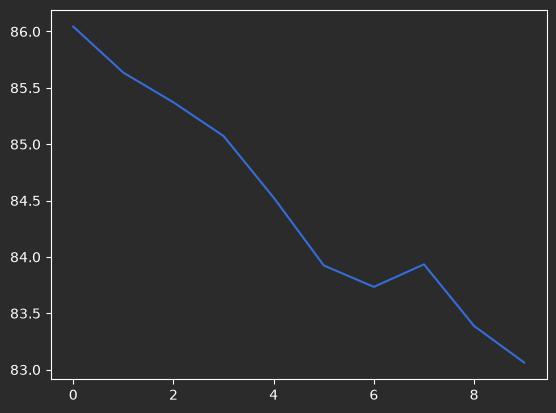

step   10  reconstruction loss 82.1494388206113


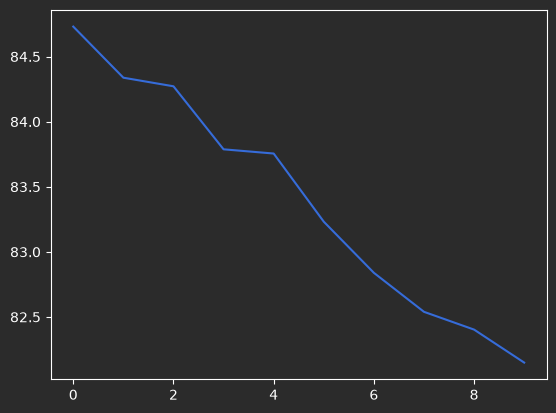

step   10  reconstruction loss 73.3943745975486


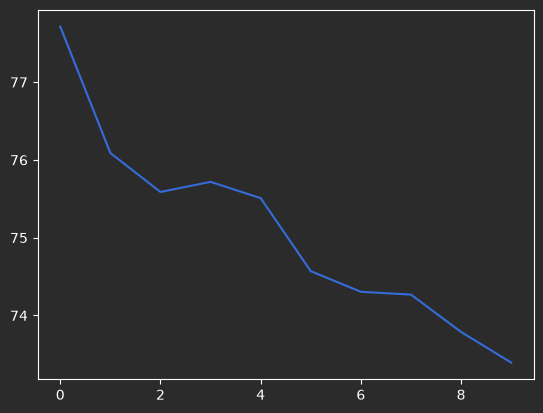

step   10  reconstruction loss 75.1833715277416


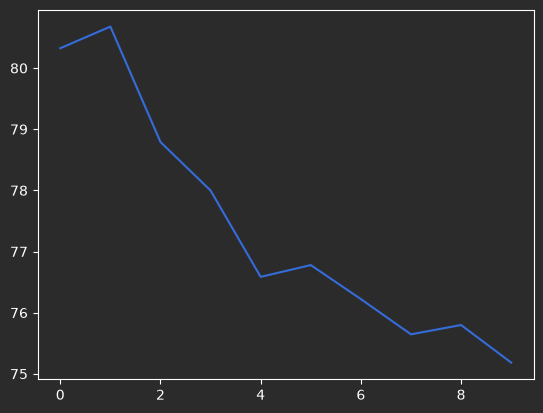

step   10  reconstruction loss 70.96609150070886


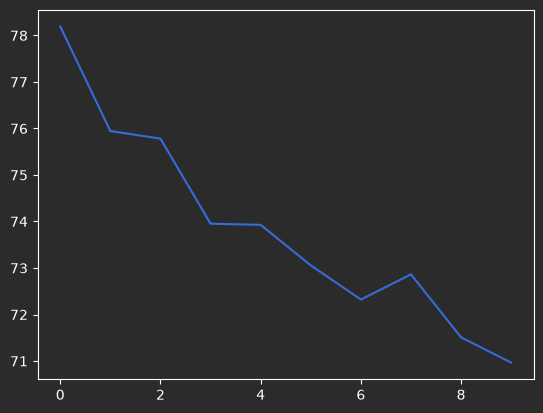

step   10  reconstruction loss 74.35432968288009


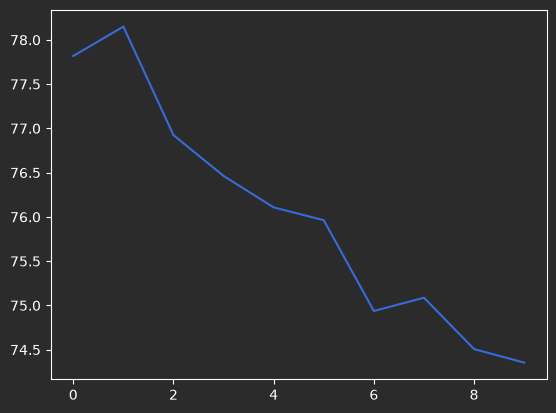

step   10  reconstruction loss 71.62203440453705


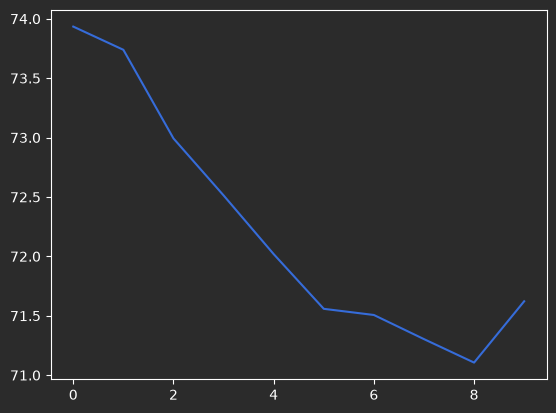

step   10  reconstruction loss 83.712113635208


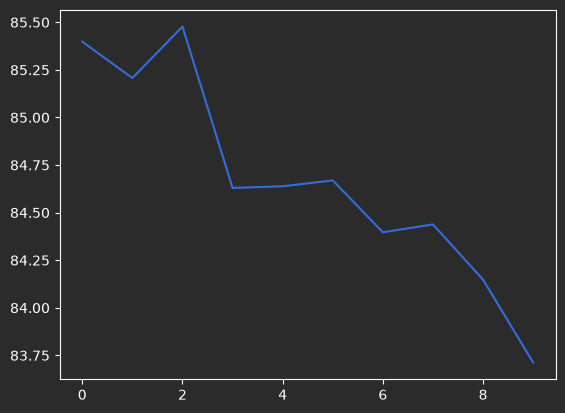

step   10  reconstruction loss 78.58849538063518


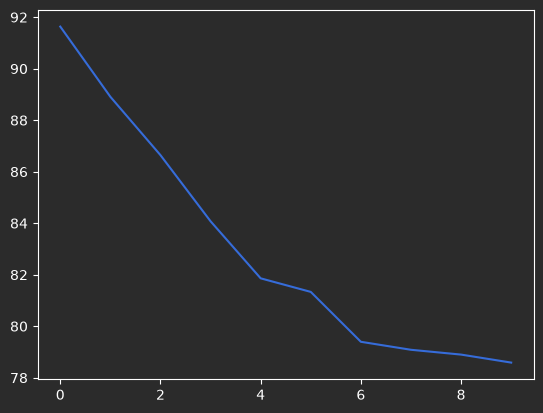

step   10  reconstruction loss 83.15570569661844


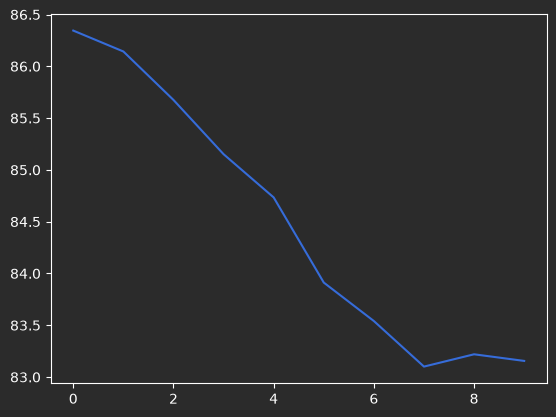

step   10  reconstruction loss 75.39515853952227


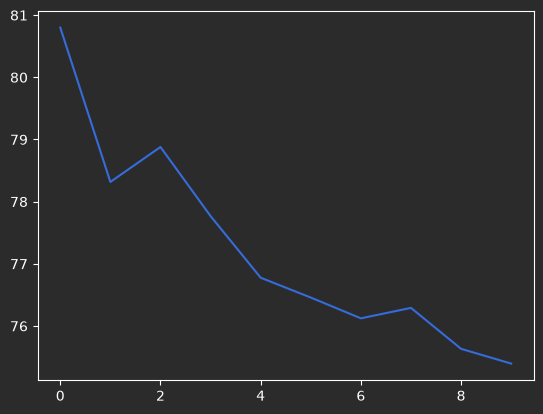

step   10  reconstruction loss 73.79753288763608


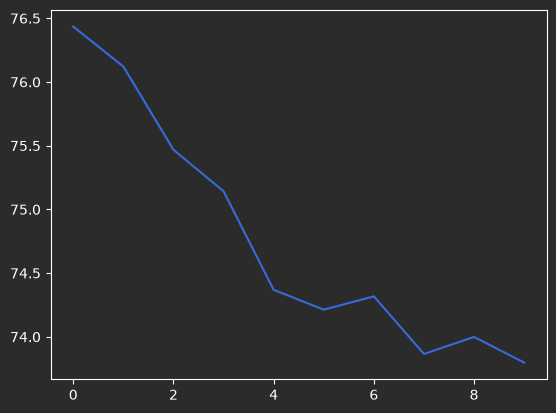

step   10  reconstruction loss 90.14654240779548


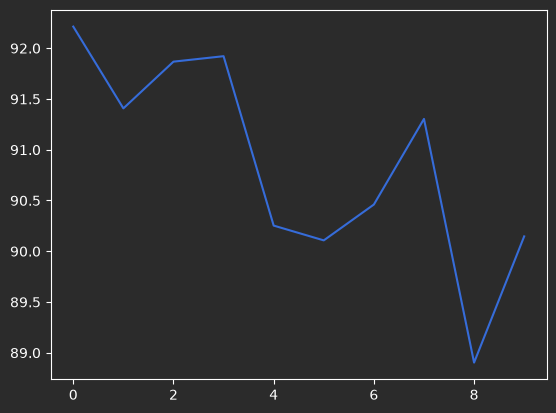

step   10  reconstruction loss 77.84121129616277


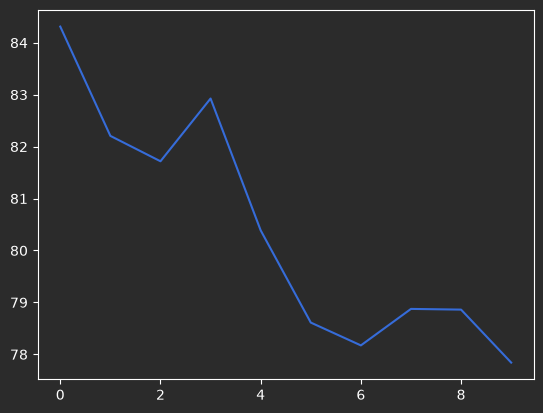

step   10  reconstruction loss 95.06547040601255


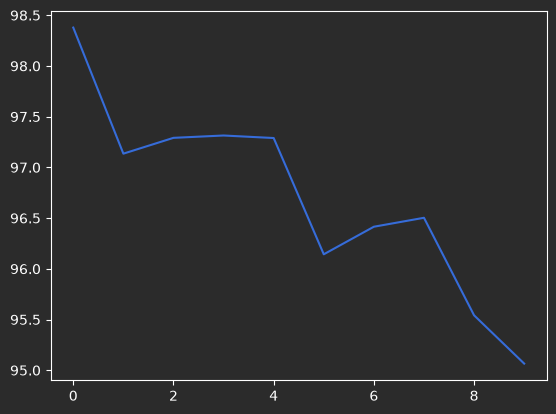

step   10  reconstruction loss 116.96233855769472


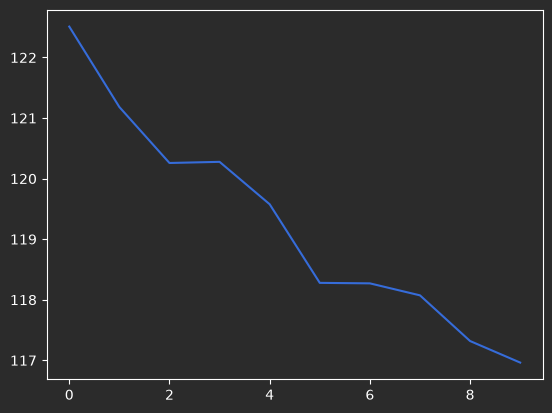

step   10  reconstruction loss 85.84656621779958


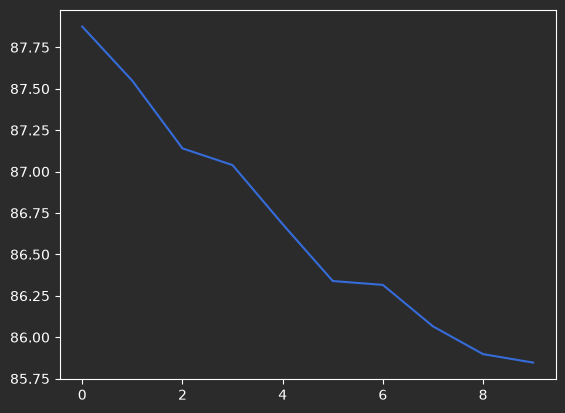

step   10  reconstruction loss 92.04285148467665


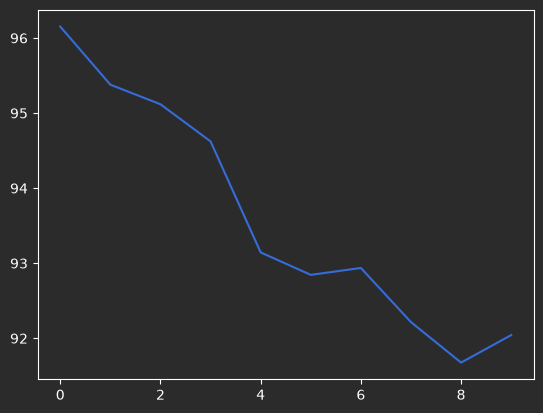

step   10  reconstruction loss 78.54998219077221


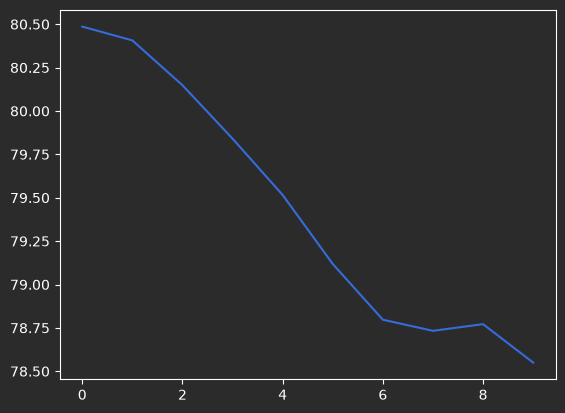

In [ ]:
# AND this is how we train:
%pdb on
BATCH_SIZE = 10
EPOCHS = 10
STEPS_PER_SAMPLE = 10
LR = 6e-4
DIVI = 5

loss = MSELoss()
optimizer = Adam(LR)
all_losses = []
verbose = True
idx_shuffler = np.arange(len(xs))


for epoch in range(1, EPOCHS):
    net.train()
    print(f'EPOCH {epoch}, lr decaying to {LR}')
    np.random.shuffle(idx_shuffler)

    # decay rate for LR
    optimizer.learning_rate = LR * (0.96 ** epoch)

    _permuted_xs = xs[idx_shuffler, ...]
    _permuted_mask = padding_mask[idx_shuffler, ...]
    for step_i, batch_st in enumerate(range(0, len(xs), BATCH_SIZE)):
        verbose = (step_i + 1) % DIVI == 0

        _xs = _permuted_xs[batch_st:batch_st+BATCH_SIZE, :, :]
        _pad = _permuted_mask[batch_st:batch_st+BATCH_SIZE, :]

        # lazy workaround -- continue back to steps/batch if we don't have enough samples left
        if _xs.shape[0] != BATCH_SIZE:
            continue

        for _ in range(STEPS_PER_SAMPLE):

            x_prime = net.forward(_xs, mask=_pad)

            reconstruction_loss = loss.forward(prediction=x_prime,
                                               targets=_xs,
                                               mask=_pad)

            all_losses.append(reconstruction_loss.item())

            net.backward(loss.backward())
            optimizer.step(net)
            net.zero_gradients()

        if verbose:
            print(f"step {_ + 1:4d}  reconstruction loss {reconstruction_loss}")
            plt.plot(all_losses[-STEPS_PER_SAMPLE:])
            plt.show()
            net.serialize("elephant_spectre_enc_dec_reconstruction.ergalio")

    print(f"step {step_i + 1:4d}  reconstruction loss {reconstruction_loss}")
    plt.plot(all_losses)
    plt.title("reconstruction loss")
    plt.show()
    net.serialize("elephant_spectre_enc_dec_reconstruction.ergalio")

plt.figure()
plt.plot(all_losses)
plt.title(f"reconstruction loss_{epoch}")
plt.ylabel("reconstruction_loss as MSE")
plt.xlabel("steps")
plt.savefig(f"reconstruction loss_{epoch}.png")
plt.show()

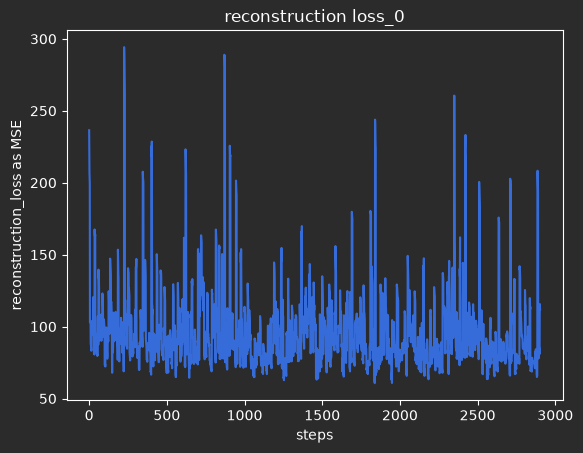

{'type': 'Network',
 'version': '0.1.8',
 'config': {'name': 'audio_encoder_decoder',
  'input_shape': (200,),
  'data_type': numpy.float32,
  'complex_data_type': numpy.complex64},
 'state': {'nodes': {'amp_embedding': {'sources': ['input'],
    'component': {'type': 'FullyConnectedLayer',
     'version': '0.1.8',
     'config': {'input_dimension': 200,
      'output_dimension': 1200,
      'activation_type': 'linear',
      'is_output': False,
      'initialization_override': None,
      'initialization_kwargs': {}},
     'state': {'weights': array([[ 0.07404209,  0.07210848, -0.03274259, ..., -0.12137289,
              -0.05467526,  0.03750984],
             [ 0.06208775, -0.08089738,  0.06047452, ...,  0.07833868,
              -0.02986009,  0.03282732],
             [-0.02263473,  0.0182921 , -0.01941399, ...,  0.01805077,
               0.06302726,  0.08150995],
             ...,
             [ 0.05282608,  0.0360566 , -0.00603363, ...,  0.03745338,
               0.0573831 , -0.

In [25]:
plt.figure()
plt.plot(all_losses)
plt.title(f"reconstruction loss_{epoch}")
plt.ylabel("reconstruction_loss as MSE")
plt.xlabel("steps")
plt.savefig(f"reconstruction loss_{epoch}.png")
plt.show()
net.purge()
net.serialize("elephant_spectre_enc_dec_reconstruction.ergalio")

In [ ]:
windowed_data.shape
x_prime.shape
plt.plot(all_losses)
plt.title("reconstruction loss")
plt.show()

In [ ]:
net.eval()
_xs = _permuted_xs[batch_st:batch_st+BATCH_SIZE, :, :]
_pad = _permuted_mask[batch_st:batch_st+BATCH_SIZE, :]
x_prime = net.forward(_xs, mask=_pad)


In [ ]:
idx=5
plt.figure()
plt.subplot(2,2, 1)
plt.plot(x_prime[0, idx, :])
plt.subplot(2,2, 2)
plt.plot(_xs[0, idx, :])

In [ ]:
# visualize some of the input data and predictions

for idx in range(min(x_prime.shape[0], 3)):
    plt.figure()
    plt.subplot(2,2, 1)
    plt.plot(x_prime[idx, 3, :])
    plt.subplot(2,2, 2)
    plt.plot(xs[0, 3, :])
    plt.show()
    plt.subplot(2,2, (3,4))
    plt.plot((x_prime[idx, 3, :] - xs[idx, 3, :]), color="red", alpha=0.2)
    plt.show()